# CMOS Inverter: Transfer Curve, Noise Margins and Dynamic Power

**Project submitted to the IEEE SSCS Code-a-Chip Travel Grant (ISSCC 2027).**

**Author:** Ronyson P. BLAISE (solo project)
**Tool:** ngspice (open-source SPICE simulator), executed in Google Colab. Any recent ngspice version works (tested with the version installed by `apt` on Colab).

Goal: simulate a CMOS inverter with **ngspice** (open-source simulator),
and extract three fundamental quantities of digital design:

1. the **voltage transfer curve** (input -> output);
2. the **noise margins** (robustness against disturbances);
3. the **dynamic power** (`P = C * V^2 * f`), measured and then compared with theory.

Honesty note: this notebook uses generic MOS models (LEVEL=1).
They are enough to understand the concepts. For real silicon numbers,
an open-source PDK (e.g. SkyWater 130 nm) would replace these models.


## Step 0 — install ngspice (once per Colab session)


In [1]:
!apt update -qq
!apt install -y -qq ngspice
!ngspice -v


3 packages can be upgraded. Run 'apt list --upgradable' to see them.


ngspice is already the newest version (42+ds-3build1).


0 upgraded, 0 newly installed, 0 to remove and 3 not upgraded.


******
** ngspice-42 : Circuit level simulation program
** Compiled with KLU Direct Linear Solver
** The U. C. Berkeley CAD Group
** Copyright 1985-1994, Regents of the University of California.
** Copyright 2001-2023, The ngspice team.
** Please get your ngspice manual from https://ngspice.sourceforge.io/docs.html
** Please file your bug-reports at http://ngspice.sourceforge.net/bugrep.html
** Creation Date: Sun Mar 31 20:15:14 UTC 2024
******


## Step 1 — write the circuit and simulate the transfer curve

The inverter (one PMOS + one NMOS) is described in the ngspice netlist language,
then the input is swept from 0 to 1.8 V (`.dc` analysis).


In [2]:
netlist_dc = """* CMOS inverter - transfer curve
Vdd vdd 0 1.8
Vin in 0 0
M1 out in vdd vdd pmos W=2u L=0.18u
M2 out in 0 0 nmos W=1u L=0.18u
.model nmos NMOS(LEVEL=1 VTO=0.4 KP=170u LAMBDA=0.01)
.model pmos PMOS(LEVEL=1 VTO=-0.4 KP=60u LAMBDA=0.01)
.dc Vin 0 1.8 0.02
.control
run
wrdata /tmp/inv_dc.txt v(in) v(out)
.endc
.end
"""
open('/tmp/inv_dc.cir', 'w').write(netlist_dc)
print("DC circuit written")

!ngspice -b -o /tmp/inv_dc.log /tmp/inv_dc.cir > /dev/null 2>&1
print("DC simulation done")

import numpy as np
d = np.loadtxt('/tmp/inv_dc.txt')
vin = d[:, 0]
# ngspice writes [sweep, vector] for each requested vector:
# the output is identified by its signature (starts high ~1.8 V, ends low ~0 V).
col_vout = [j for j in range(d.shape[1]) if d[0, j] > 1.0 and d[-1, j] < 0.2][0]
vout = d[:, col_vout]
print("simulated points:", len(vin))
print("Vout at Vin=0 V :", round(float(vout[0]), 3), "V")
print("Vout at Vin=1.8 V :", round(float(vout[-1]), 3), "V")


DC circuit written


DC simulation done


simulated points: 91
Vout at Vin=0 V : 1.8 V
Vout at Vin=1.8 V : 0.0 V


## Step 2 — plot the transfer curve


/home/hatch/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


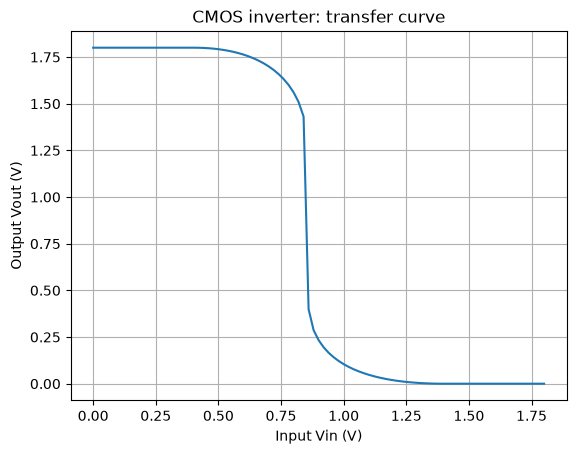

In [3]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(vin, vout)
plt.xlabel("Input Vin (V)")
plt.ylabel("Output Vout (V)")
plt.title("CMOS inverter: transfer curve")
plt.grid(True)
plt.show()


## Step 3 — noise margins

In plain words: how much disturbance the input can tolerate before the output is wrong.

- `V_IL` / `V_IH`: the two input voltages where the curve's slope equals -1;
- `V_OH` / `V_OL`: high / low output (1.8 V / 0 V here);
- low margin `NM_L = V_IL - V_OL`, high margin `NM_H = V_OH - V_IH`.


V_OH = 1.8 V
V_OL = 0.0 V
V_IL = 0.715 V
V_IH = 0.971 V
Low noise margin NM_L = 0.715 V
High noise margin NM_H = 0.829 V


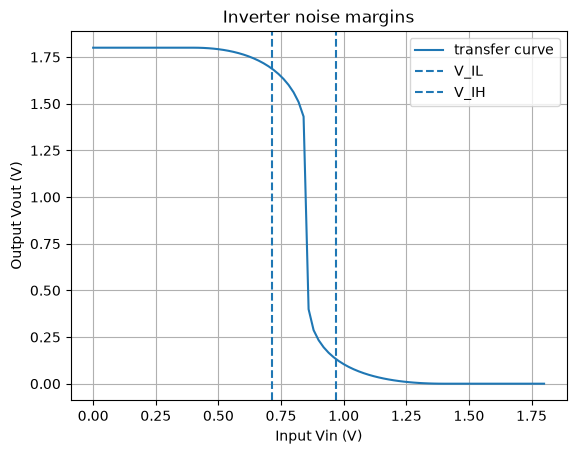

In [4]:
V_OH = float(vout[0])
V_OL = float(vout[-1])
pente = np.gradient(vout, vin)
passages = np.where(np.diff(np.sign(pente + 1)))[0]
i1 = passages[0]
i2 = passages[1]
V_IL = float(vin[i1] + (vin[i1+1] - vin[i1]) * (0 - (pente[i1] + 1)) / ((pente[i1+1] + 1) - (pente[i1] + 1)))
V_IH = float(vin[i2] + (vin[i2+1] - vin[i2]) * (0 - (pente[i2] + 1)) / ((pente[i2+1] + 1) - (pente[i2] + 1)))
NM_L = V_IL - V_OL
NM_H = V_OH - V_IH

print("V_OH =", round(V_OH, 3), "V")
print("V_OL =", round(V_OL, 3), "V")
print("V_IL =", round(V_IL, 3), "V")
print("V_IH =", round(V_IH, 3), "V")
print("Low noise margin NM_L =", round(NM_L, 3), "V")
print("High noise margin NM_H =", round(NM_H, 3), "V")

plt.figure()
plt.plot(vin, vout, label="transfer curve")
plt.axvline(V_IL, linestyle="--", label="V_IL")
plt.axvline(V_IH, linestyle="--", label="V_IH")
plt.xlabel("Input Vin (V)")
plt.ylabel("Output Vout (V)")
plt.title("Inverter noise margins")
plt.legend()
plt.grid(True)
plt.show()


## Step 4 — dynamic power: transient simulation

The inverter is now switched at 10 MHz with a 10 fF load at the output,
and the current drawn from the supply is measured. Power = voltage x average current.


In [5]:
netlist_tran = """* CMOS inverter - dynamic power
Vdd vdd 0 1.8
Vin in 0 PULSE(0 1.8 0 0.2n 0.2n 49n 100n)
M1 out in vdd vdd pmos W=2u L=0.18u
M2 out in 0 0 nmos W=1u L=0.18u
Cload out 0 10f
.model nmos NMOS(LEVEL=1 VTO=0.4 KP=170u LAMBDA=0.01)
.model pmos PMOS(LEVEL=1 VTO=-0.4 KP=60u LAMBDA=0.01)
.tran 0.05n 500n 0 0.05n
.control
run
wrdata /tmp/vin_t.txt v(in)
wrdata /tmp/vout_t.txt v(out)
wrdata /tmp/idd_t.txt i(Vdd)
.endc
.end
"""
open('/tmp/inv_tran.cir', 'w').write(netlist_tran)
print("transient circuit written")

!ngspice -b -o /tmp/inv_tran.log /tmp/inv_tran.cir > /dev/null 2>&1
print("transient simulation done")


transient circuit written


transient simulation done


## Step 5 — waveforms: the input switches, the output follows inverted


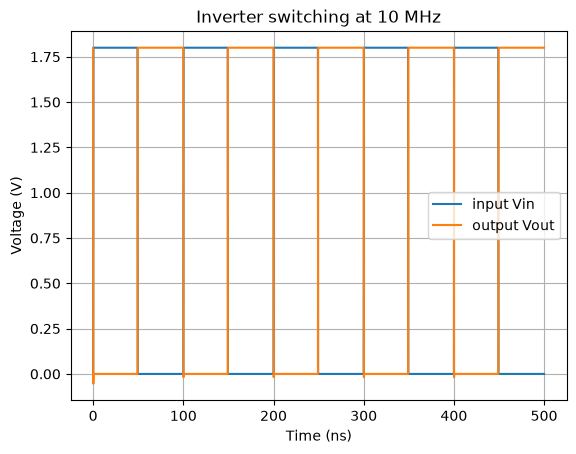

In [6]:
# one vector per file -> each file is [time, vector]: direct reading.
t_vin = np.loadtxt('/tmp/vin_t.txt')
t_vout = np.loadtxt('/tmp/vout_t.txt')
temps = t_vin[:, 0]
vin_t = t_vin[:, 1]
vout_t = t_vout[:, 1]

plt.figure()
plt.plot(temps * 1e9, vin_t, label="input Vin")
plt.plot(temps * 1e9, vout_t, label="output Vout")
plt.xlabel("Time (ns)")
plt.ylabel("Voltage (V)")
plt.title("Inverter switching at 10 MHz")
plt.legend()
plt.grid(True)
plt.show()


## Step 6 — measured power vs theory `P = C * V^2 * f`

Theory says that at each switching event, the supply delivers `C * V^2` joules.
At 10 MHz: `P = C * V^2 * f`. Let us compare with the measurement.


In [7]:
t2 = np.loadtxt('/tmp/idd_t.txt')
temps_i = t2[:, 0]
idd = t2[:, 1]

Vdd = 1.8
C = 10e-15
f = 10e6
# time-weighted average (simulation steps are not uniform);
# the first period is ignored (start-up transient).
fenetre = (temps_i >= 100e-9) & (temps_i <= 500e-9)
P_mesuree = -Vdd * np.trapezoid(idd[fenetre], temps_i[fenetre]) / (400e-9)
P_formule = 1.0 * C * Vdd**2 * f

print("Measured power (simulation):", round(P_mesuree * 1e6, 3), "uW")
print("Formula power (C*V^2*f)    :", round(P_formule * 1e6, 3), "uW")
print("Gap:", round(100 * (P_mesuree - P_formule) / P_formule, 1), "%")
print("The gap comes from short-circuit power:")
print("during each input transition, both transistors conduct for a brief moment.")


Measured power (simulation): 0.406 uW
Formula power (C*V^2*f)    : 0.324 uW
Gap: 25.2 %
The gap comes from short-circuit power:
during each input transition, both transistors conduct for a brief moment.


## Conclusion

With a 100% open-source and free simulator, this notebook has:

- plotted the **transfer curve** of a CMOS inverter;
- extracted the **noise margins** (thresholds `V_IL`/`V_IH`, margins `NM_L`/`NM_H`);
- **measured the dynamic power** and compared it with the theory `P = C*V^2*f`,
  honestly identifying the gap (short-circuit current during transitions).

Known limitation: generic MOS models (LEVEL=1), not a foundry PDK.
Extension idea: plug in the open-source SkyWater 130 nm PDK and redo the three measurements.

*To submit to Code-a-Chip: place this notebook + a LICENSE file (Apache 2.0)
in `ISSCC27/submitted_notebooks/<project-name>/` via a GitHub Pull Request.*
